## Stage 5: Predicting Late Deliveries
**Research question 2:** Can we predict at the time of purchase whether an order will be delivered late?


In [10]:
from google.colab import files
uploaded = files.upload()

Saving olist_customers_dataset.csv to olist_customers_dataset.csv
Saving olist_geolocation_dataset.csv to olist_geolocation_dataset.csv
Saving olist_model_data.csv to olist_model_data.csv
Saving olist_order_items_dataset.csv to olist_order_items_dataset.csv
Saving olist_order_payments_dataset.csv to olist_order_payments_dataset.csv
Saving olist_order_reviews_dataset.csv to olist_order_reviews_dataset.csv
Saving olist_orders_dataset.csv to olist_orders_dataset.csv
Saving olist_products_dataset.csv to olist_products_dataset.csv
Saving olist_sellers_dataset.csv to olist_sellers_dataset.csv
Saving product_category_name_translation.csv to product_category_name_translation.csv


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             precision_recall_curve, classification_report)

In [12]:
df = pd.read_csv('olist_model_data.csv',
                 parse_dates=['order_purchase_timestamp', 'order_estimated_delivery_date'])

df['promised_days'] = (df['order_estimated_delivery_date'] - df['order_purchase_timestamp']).dt.days
df['purchase_dow'] = df['order_purchase_timestamp'].dt.dayofweek
df['purchase_month_num'] = df['order_purchase_timestamp'].dt.month
df['multi_seller'] = (df['n_sellers'] > 1).astype(int)
df['same_state'] = df['same_state'].astype(int)
df['is_late'] = df['is_late'].astype(int)

features_num = ['log_price', 'log_freight', 'log_weight', 'distance_km', 'n_items',
                'multi_seller', 'same_state', 'promised_days',
                'purchase_dow', 'purchase_month_num']
features_cat = ['category_grouped', 'customer_state', 'seller_state']

df[features_cat] = df[features_cat].fillna('unknown')
df = df.dropna(subset=features_num).copy()

print(df.shape)
print('Gecikmə payı:', round(df['is_late'].mean(), 3))

(95991, 39)
Gecikmə payı: 0.068


In [13]:
X = df[features_num + features_cat]
y = df['is_late']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (76792, 13)  Test: (19199, 13)


In [14]:
baseline_acc = 1 - y_test.mean()
print('Həmişə "gecikməyəcək" desək, accuracy:', round(baseline_acc, 3))
print('Təsadüfi modelin PR-AUC-u (gecikmə payı):', round(y_test.mean(), 3))

Həmişə "gecikməyəcək" desək, accuracy: 0.932
Təsadüfi modelin PR-AUC-u (gecikmə payı): 0.068


In [15]:
preprocess = ColumnTransformer([
    ('num', StandardScaler(), features_num),
    ('cat', OneHotEncoder(handle_unknown='ignore'), features_cat)
])

In [16]:
logreg = Pipeline([
    ('prep', preprocess),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))
])

logreg.fit(X_train, y_train)
p_logreg = logreg.predict_proba(X_test)[:, 1]

print('Logistic Regression')
print('  ROC-AUC:', round(roc_auc_score(y_test, p_logreg), 3))
print('  PR-AUC :', round(average_precision_score(y_test, p_logreg), 3))

Logistic Regression
  ROC-AUC: 0.708
  PR-AUC : 0.148


In [17]:
rf = Pipeline([
    ('prep', preprocess),
    ('model', RandomForestClassifier(n_estimators=200, min_samples_leaf=20,
                                     class_weight='balanced_subsample',
                                     n_jobs=-1, random_state=42))
])

rf.fit(X_train, y_train)
p_rf = rf.predict_proba(X_test)[:, 1]

print('Random Forest')
print('  ROC-AUC:', round(roc_auc_score(y_test, p_rf), 3))
print('  PR-AUC :', round(average_precision_score(y_test, p_rf), 3))

Random Forest
  ROC-AUC: 0.779
  PR-AUC : 0.242


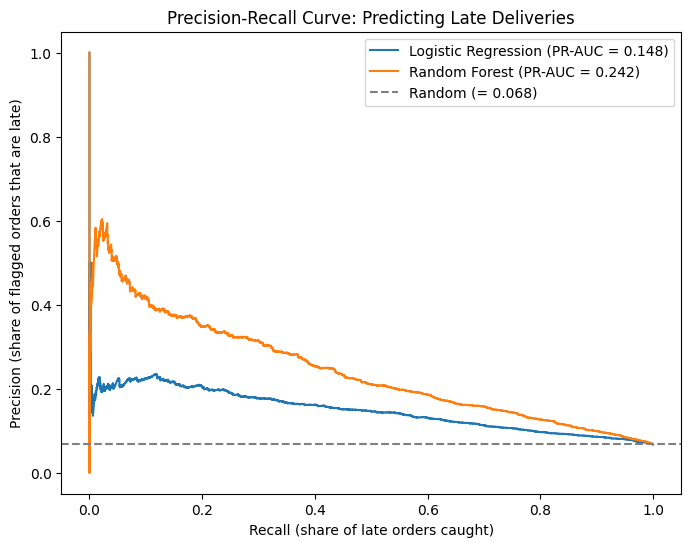

In [18]:
plt.figure(figsize=(8, 6))
for name, p in [('Logistic Regression', p_logreg), ('Random Forest', p_rf)]:
    precision, recall, _ = precision_recall_curve(y_test, p)
    ap = average_precision_score(y_test, p)
    plt.plot(recall, precision, label=f'{name} (PR-AUC = {ap:.3f})')

plt.axhline(y_test.mean(), color='gray', linestyle='--', label=f'Random (= {y_test.mean():.3f})')
plt.xlabel('Recall (share of late orders caught)')
plt.ylabel('Precision (share of flagged orders that are late)')
plt.title('Precision-Recall Curve: Predicting Late Deliveries')
plt.legend()
plt.show()

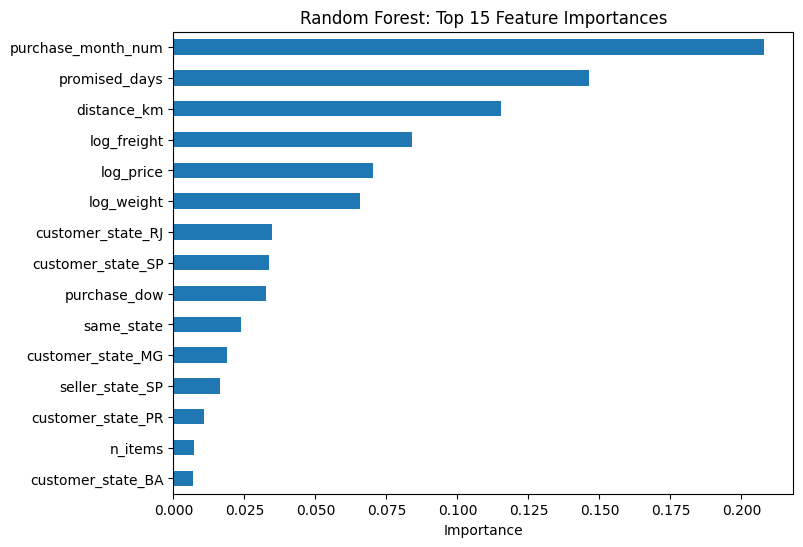

In [19]:
feature_names = rf.named_steps['prep'].get_feature_names_out()
importances = pd.Series(rf.named_steps['model'].feature_importances_, index=feature_names)
importances.index = importances.index.str.replace('num__', '').str.replace('cat__', '')

importances.sort_values().tail(15).plot(kind='barh', figsize=(8, 6))
plt.title('Random Forest: Top 15 Feature Importances')
plt.xlabel('Importance')
plt.show()

In [20]:
print(classification_report(y_test, (p_rf >= 0.5).astype(int),
                            target_names=['On time', 'Late']))

              precision    recall  f1-score   support

     On time       0.96      0.84      0.90     17901
        Late       0.20      0.54      0.29      1298

    accuracy                           0.82     19199
   macro avg       0.58      0.69      0.59     19199
weighted avg       0.91      0.82      0.86     19199



### Robustness check: time-based split

In [21]:
df_sorted = df.sort_values('order_purchase_timestamp')
cutoff = df_sorted['order_purchase_timestamp'].quantile(0.8)

train_t = df_sorted[df_sorted['order_purchase_timestamp'] < cutoff]
test_t = df_sorted[df_sorted['order_purchase_timestamp'] >= cutoff]

print('Cutoff tarixi:', cutoff.date())
print('Train:', train_t.shape, ' Test:', test_t.shape)
print('Test dövründə gecikmə payı:', round(test_t['is_late'].mean(), 3))

Cutoff tarixi: 2018-05-26
Train: (76792, 39)  Test: (19199, 39)
Test dövründə gecikmə payı: 0.035


In [22]:
results = []
num_without_month = [c for c in features_num if c != 'purchase_month_num']

for name, num_cols in [('with month', features_num), ('without month', num_without_month)]:
    prep = ColumnTransformer([
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), features_cat)
    ])
    model = Pipeline([
        ('prep', prep),
        ('model', RandomForestClassifier(n_estimators=200, min_samples_leaf=20,
                                         class_weight='balanced_subsample',
                                         n_jobs=-1, random_state=42))
    ])
    cols = num_cols + features_cat
    model.fit(train_t[cols], train_t['is_late'])
    p = model.predict_proba(test_t[cols])[:, 1]
    results.append({
        'model': name,
        'ROC-AUC': roc_auc_score(test_t['is_late'], p),
        'PR-AUC': average_precision_score(test_t['is_late'], p),
        'random PR-AUC': test_t['is_late'].mean()
    })

pd.DataFrame(results).round(3)

,model,ROC-AUC,PR-AUC,random PR-AUC
0,with month,0.652,0.058,0.035
1,without month,0.577,0.047,0.035


### Key findings: Stage 5
- Random Forest outperformed Logistic Regression on a random split
  (PR-AUC 0.24 vs 0.15; random baseline 0.07), suggesting non-linear effects.
- Accuracy is misleading: always predicting "on time" gives 93% accuracy
  but catches no late orders. PR-AUC was used instead.
- The most important feature was purchase month, a warning sign:
  delays cluster in specific periods (Nov 2017, Feb–Mar 2018).
- With a time-based split (train before 26 May 2018, test after),
  PR-AUC fell to 0.06 (baseline 0.035): the random split overestimated
  real-world performance.
- Test-period late rate was only 3.5%, reflecting both distribution shift
  and right-censoring of recent orders.
- Conclusion: late deliveries are only weakly predictable at the time of purchase;
  most delay drivers likely occur after purchase and are not in the data.
  

In [ ]:
from google.colab import drive
drive.mount('/content/drive')